config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

gpt2: 12 layers x 12 heads
   'it' attends most to: [('The', 0.68), ('because', 0.13), ('street', 0.04), ('animal', 0.03)]
   per-head target of 'it': ['The', 'The', 'The', 'The', 'because', 'The', 'The', 'The', 'The', 'The', 'The', 'The']


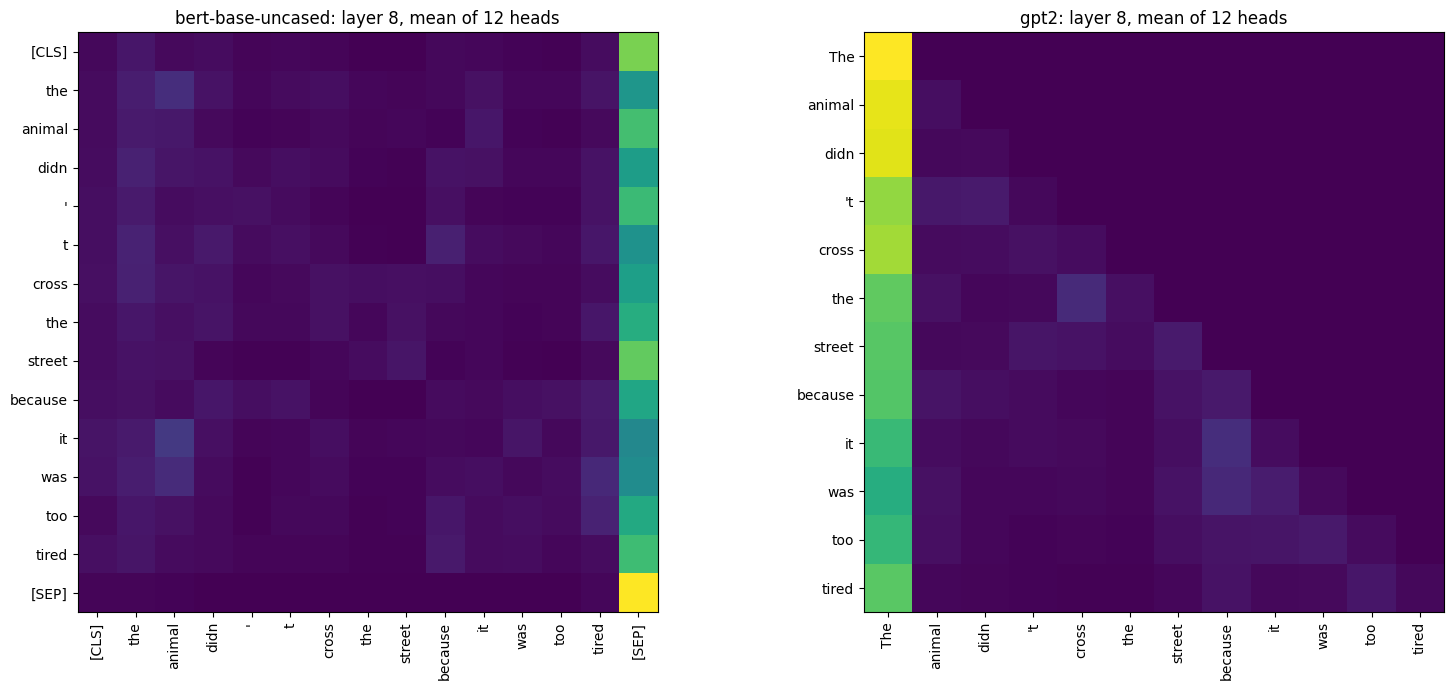

Note: BERT's map is full (every token sees left and right context).
GPT-2's map is lower-triangular (causal mask: a token only sees earlier tokens).


In [1]:
# Experiment 9: Visualise real attention weights in BERT (encoder, bidirectional) and GPT-2 (decoder, causal)
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

sentence = "The animal didn't cross the street because it was too tired"
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model_id in zip(axes, ["bert-base-uncased", "gpt2"]):
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id, output_attentions=True, attn_implementation="eager").eval()
    enc = tok(sentence, return_tensors="pt")
    with torch.no_grad():
        attentions = model(**enc).attentions          # one tensor per layer: (batch, heads, tokens, tokens)
    tokens = [t.replace("\u0120", "") for t in tok.convert_ids_to_tokens(enc.input_ids[0])]
    layer = len(attentions) - 4                       # an upper-middle layer
    avg = attentions[layer][0].mean(0)                # average over heads
    ax.imshow(avg.numpy(), cmap="viridis")
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens)
    ax.set_title(f"{model_id}: layer {layer}, mean of {attentions[layer].shape[1]} heads")
    print(f"{model_id}: {len(attentions)} layers x {attentions[0].shape[1]} heads")

    # Annotation: which words does "it" attend to?
    i = tokens.index("it")
    top = avg[i].topk(4)
    print("   'it' attends most to:", [(tokens[j], round(float(v), 2)) for v, j in zip(top.values, top.indices)])

    # Per-head view: strongest attention target of 'it' in every head of that layer
    heads = attentions[layer][0, :, i].argmax(-1)
    print("   per-head target of 'it':", [tokens[j] for j in heads])

plt.tight_layout(); plt.show()
print("Note: BERT's map is full (every token sees left and right context).")
print("GPT-2's map is lower-triangular (causal mask: a token only sees earlier tokens).")